# Cross-Sectional Asset Pricing

Two portfolios can have different average returns because they carry different exposures, because the benchmark misses an important return dimension, or because realized outcomes are noisy. Cross-sectional asset pricing asks whether a common price for each exposure can account for these differences across investments.

Notebook 04 evaluated candidate factors against a market benchmark. Here we turn to a cross-section of portfolios: do portfolios with greater market exposure earn higher average excess returns, and does the relationship agree with CAPM? We first explain the pricing restriction and two-pass estimation. We then apply the method to 25 published Size × Book-to-Market portfolios, keeping market beta as the single exposure so that the estimated relationship can be examined directly.

In [1]:
import sys
from pathlib import Path
ROOT=Path.cwd().resolve()
ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
NAVY, BLUE, GREEN, ORANGE, GRAY = '#17324D', '#2878A5', '#168A86', '#D99A32', '#737D87'
STYLE={'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,'axes.labelsize':11,
       'xtick.labelsize':10,'ytick.labelsize':10,'legend.fontsize':10,'figure.dpi':110,
       'figure.facecolor':'white','axes.facecolor':'white','axes.spines.top':False,
       'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=[BLUE,GREEN,ORANGE,NAVY]),
       'grid.alpha':.15,'lines.linewidth':1.8}
plt.rcParams.update(STYLE)
SIGNED=LinearSegmentedColormap.from_list('ocean_white_amber',[BLUE,'white',ORANGE])
from factor_asset_pricing.asset_pricing_tests import two_pass_fama_macbeth
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"


## 1. Cross-sectional asset pricing

### 1.1 From factor exposure to expected return

A time-series regression describes how a portfolio moves with a factor. An asset-pricing model adds a restriction on its expected return: portfolios with the same exposure should receive the same model-implied compensation for that exposure. In a general linear model,

$$E[R_i^e]=\boldsymbol\beta_i'\boldsymbol\lambda,$$

where $R_i^e=R_i-R_f$, $\boldsymbol\beta_i$ contains portfolio $i$'s factor exposures, and $\boldsymbol\lambda$ contains the common expected compensation per unit of exposure. Exposure and compensation are different objects. A portfolio can move strongly with a factor even when the associated expected compensation is small.

For CAPM, this becomes

$$E[R_i^e]=\beta_{i,M}\lambda_M,\qquad\lambda_M=E[MKT].$$

Under the model, another unit of market beta earns another unit of the expected market premium. The security market line expresses this relation across investments, with beta on the horizontal axis and expected excess return on the vertical axis. It differs from 04's scatterplots of contemporaneous monthly returns.

For correctly priced traded factors with nonsingular covariance, the general pricing restriction implies $\boldsymbol\lambda=E[\mathbf F]$. Freely estimated cross-sectional prices need not satisfy that restriction. They measure the return differences associated with exposures in the selected test assets. Such an association does not establish a structural economic source of priced risk.

### 1.2 Estimating exposures and their compensation

Neither population betas nor expected returns are observed. Two-pass estimation replaces both with information from historical returns.

**First pass: estimate exposures.** For each portfolio, estimate the time-series regression introduced in 04:

$$R_{i,t}^e=\alpha_i+\beta_{i,M}MKT_t+\varepsilon_{i,t}.$$

The estimated $\widehat\beta_{i,M}$ describes its market exposure. We retain the time-series intercept when estimating beta, rather than imposing the pricing restriction before examining it.

**Second pass: compare returns across exposures.** In each month, regress the portfolios' realized excess returns on their estimated betas:

$$R_{i,t}^e=\gamma_{0,t}+\widehat\beta_{i,M}\lambda_{M,t}+\eta_{i,t}.$$

The slope is that month's cross-sectional return difference per unit of beta. Its sign can change from month to month. The common intercept is the fitted excess return at zero beta, not an individual portfolio's time-series alpha. Allowing it makes the fitted relationship more flexible than the strict CAPM restriction, which requires zero intercept and a market exposure price equal to the expected market premium.

With $N$ portfolios, let $Z$ contain a column of ones and a column of estimated betas. The monthly coefficient vector is

$$\widehat{\boldsymbol\gamma}_t=(Z'Z)^{-1}Z'\mathbf r_t^e,\qquad\boldsymbol\gamma_t=(\gamma_{0,t},\lambda_{M,t})'.$$

The portfolios must have sufficiently different exposures to identify the slope. Narrow beta dispersion makes it harder to distinguish an intercept from compensation for beta. This is especially relevant when extrapolating the fitted line to zero beta.

### 1.3 Fama–MacBeth estimates and inference

The Fama–MacBeth procedure averages the monthly cross-sectional coefficients (Fama and MacBeth, 1973):

$$\widehat\lambda_M=\frac1T\sum_{t=1}^T\widehat\lambda_{M,t},\qquad
\widehat\gamma_0=\frac1T\sum_{t=1}^T\widehat\gamma_{0,t}.$$

A monthly slope describes one realized cross-section. Its average estimates persistent compensation per unit of market exposure. For a balanced panel with fixed betas and identical regressors each month, this average equals the slope obtained by regressing the portfolios' sample mean excess returns on those betas. The repeated monthly estimates additionally supply a time series for inference.

If monthly slopes were independent and identically distributed, the standard error of their mean would be

$$SE(\widehat\lambda_M)=\frac{s(\widehat\lambda_{M,t})}{\sqrt T}.$$

Dependence between months changes the uncertainty about that mean. We therefore use the Newey–West approach from 04, applied to the monthly coefficient series with 12 lags. The reported statistic is the coefficient mean divided by its HAC standard error, using an asymptotic reference distribution.

There is a separate source of uncertainty: betas are estimated in the first pass. The existing API conditions on these fixed estimated betas and does not implement a Shanken correction for their estimation error (Shanken, 1992). Its HAC statistics should be interpreted with that limitation. Full-sample betas also make this an in-sample historical analysis, rather than exposures available to an investor before each month.

### 1.4 Pricing errors and the traded-market benchmark

The fitted cross-sectional relationship predicts each portfolio's mean excess return as

$$\widehat\mu_i^e=\widehat\gamma_0+\widehat\beta_{i,M}\widehat\lambda_M.$$

Its cross-sectional pricing error is

$$\widehat e_i=\overline R_i^e-\widehat\gamma_0-\widehat\beta_{i,M}\widehat\lambda_M.$$

A positive error means the fitted relationship understates the portfolio's historical average return. A negative error means it overstates it. These errors assess the freely fitted exposure-price relationship, not necessarily the strict CAPM restriction.

Time-series alpha instead uses the observed average market premium:

$$\widehat\alpha_i=\overline R_i^e-\widehat\beta_{i,M}\overline{MKT}.$$

Thus the two errors differ whenever the fitted cross-sectional intercept is nonzero or the estimated exposure price differs from the market mean. A good fit of the freely estimated line does not establish CAPM. The model additionally requires a zero population intercept and $\lambda_M=E[MKT]$. Notebook 07 evaluates joint time-series alpha restrictions.

## 2. Example: pricing the Size × Book-to-Market portfolios

### 2.1 Data and portfolio exposures

We use the 25 published value-weighted Size × B/M portfolios and market excess returns from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html). These are published returns, rather than the internal portfolios constructed in Notebook 02. Rows run from small to big firms and columns from low to high book-to-market. This portfolio design preserves characteristic-related return differences while reducing firm-specific noise. It does not guarantee a wide range of market betas.

We retain the existing common sample: July 1964 through December 2024, comprising 726 consecutive monthly observations. The sample requires complete observations for all 25 portfolios and the supplied factor dataset, preserving the previous sample-selection convention even though the regression uses MKT alone. These are published portfolio returns; the July 1964 start preserves the earlier common sample.

The portfolio panel contains total returns. We subtract each month's matched RF once. MKT is already an excess return and is left unchanged. Calculations use decimal returns, while tables and figures express monthly means and exposure prices in percent.

In [2]:
factors = load_french("ff5", RAW).loc["1963-07":"2024-12"]
assert len(factors) == 738 and not factors.isna().any().any()
total = load_french("size_bm", RAW).loc["1964-07":"2024-12"]
sample = pd.concat([total, factors], axis=1, join="inner").dropna()
excess = sample[total.columns].sub(sample["RF"], axis=0)
display(sample_coverage(excess))
print("Empirical monthly common sample:", sample.index.min(), sample.index.max(), "T =", len(sample))


,start,end,observations,missing
S1C1,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S1C2,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S1C3,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S1C4,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S1C5,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S2C1,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S2C2,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S2C3,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S2C4,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0
S2C5,1964-07-01 00:00:00,2024-12-01 00:00:00,726,0


Empirical monthly common sample: 1964-07-01 00:00:00 2024-12-01 00:00:00 T = 726


In [3]:
fm=two_pass_fama_macbeth(excess,sample[["MKT"]],hac_lags=12,add_constant=True)
betas=fm["betas"]["MKT"]
g=fm["summary"]["estimate"]
observed=excess.mean()
market_mean=sample["MKT"].mean()
fitted=g["constant"]+betas*g["MKT"]
pricing_errors=observed-fitted
asset_order=[f"S{s}C{c}" for s in range(1,6) for c in range(1,6)]
size_colors=[NAVY,BLUE,GREEN,ORANGE,GRAY]
print(f"Estimated market betas: {betas.min():.3f} to {betas.max():.3f}")

Estimated market betas: 0.868 to 1.411


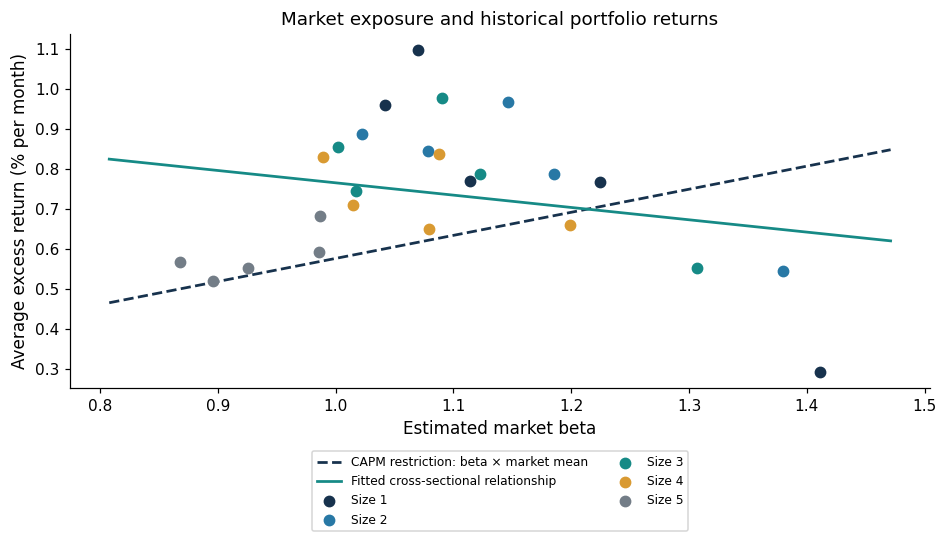

In [4]:
fig,ax=plt.subplots(figsize=(8.5,4.8),layout="constrained")
grid=np.linspace(betas.min()-.06,betas.max()+.06,150)
ax.plot(grid,100*grid*market_mean,color=NAVY,ls="--",label="CAPM restriction: beta × market mean")
ax.plot(grid,100*(g["constant"]+grid*g["MKT"]),color=GREEN,label="Fitted cross-sectional relationship")
for size,color in enumerate(size_colors,start=1):
    assets=[f"S{size}C{c}" for c in range(1,6)]
    ax.scatter(betas.loc[assets],100*observed.loc[assets],color=color,s=45,label=f"Size {size}",zorder=3)
ax.set(xlabel="Estimated market beta",ylabel="Average excess return (% per month)",title="Market exposure and historical portfolio returns")
ax.legend(fontsize=8,ncol=2,loc="upper center",bbox_to_anchor=(.5,-.16))
plt.show()

The estimated betas range from approximately 0.87 to 1.41, while average excess returns range from approximately 0.29% to 1.10% per month. Portfolios with similar market exposure can therefore have quite different historical means. The dashed line represents the CAPM restriction evaluated using the sample market mean. The solid line instead estimates both an intercept and an exposure price from these portfolios.

The fitted line slopes downward, rather than following the positive market premium. This is a feature of this selected cross-section, not evidence that greater market exposure generally commands negative expected compensation. The estimated slope's uncertainty is essential to its interpretation, as the table below shows.

### 2.2 Estimated compensation for market exposure

We report the estimated common intercept and market exposure price, their Newey–West uncertainty, and the sample market premium. For CAPM, the population intercept is zero and the exposure price equals the expected market premium. The market mean is shown as a descriptive benchmark. The reported coefficient statistics test each coefficient against zero, not the difference between the estimated exposure price and the market mean.

In [5]:
summary=fm["summary"].copy()
comparison=pd.DataFrame({
    "Estimate (%)":summary["estimate"]*100,
    "NW SE (%)":summary["standard_error"]*100,
    "NW statistic":summary["t_statistic"],
    "p-value":summary["p_value"],
    "CAPM reference (%)":[0,market_mean*100],
    "Months":summary["n_periods"].astype(int),
})
comparison.index=["Common intercept","Market exposure price"]
display(comparison)

,Estimate (%),NW SE (%),NW statistic,p-value,CAPM reference (%),Months
Common intercept,1.072945,0.432529,2.480633,0.013115,0.000000,726
Market exposure price,-0.307840,0.457808,-0.672421,0.501316,0.576267,726


The estimated exposure price is approximately −0.308% per month, with a Newey–West standard error of 0.458% and a statistic of −0.67. It is not statistically distinguishable from zero. The sample market premium is positive, approximately 0.576% per month, but the table does not supply a formal test of equality between that mean and the estimated exposure price.

The fitted intercept is approximately 1.073% per month, with a statistic of 2.48. It is significant at the nominal 5% two-sided level. Since none of the portfolios has beta near zero, interpreting it as the return on an observed zero-beta investment would be inappropriate. The intercept and slope together describe a downward fitted relationship over the observed beta range.

These estimates do not reproduce CAPM's sample reference line, and the significant intercept provides evidence against the zero-intercept restriction. The table still does not test whether the estimated exposure price equals the market mean. Nor does insignificance establish that the model is correct. The portfolios' mean-return differences and remaining errors provide additional descriptive evidence.

### 2.3 How well does market exposure explain average returns?

The observed-versus-fitted plot compares each portfolio's mean with the freely estimated cross-sectional prediction. Points on the 45-degree line would have zero cross-sectional pricing error. Both axes use the same scale, so vertical deviations show the error in percentage points per month.

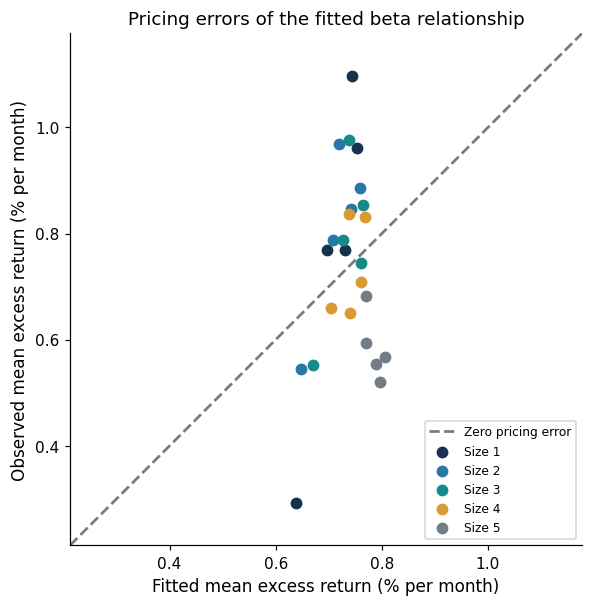

In [6]:
fig,ax=plt.subplots(figsize=(6.8,5.4),layout="constrained")
bounds=np.array([min(observed.min(),fitted.min()),max(observed.max(),fitted.max())])*100
pad=.08
limits=[bounds[0]-pad,bounds[1]+pad]
ax.plot(limits,limits,color=GRAY,ls="--",label="Zero pricing error")
for size,color in enumerate(size_colors,start=1):
    assets=[f"S{size}C{c}" for c in range(1,6)]
    ax.scatter(100*fitted.loc[assets],100*observed.loc[assets],color=color,s=45,label=f"Size {size}",zorder=3)
ax.set(xlim=limits,ylim=limits,aspect="equal",xlabel="Fitted mean excess return (% per month)",ylabel="Observed mean excess return (% per month)",title="Pricing errors of the fitted beta relationship")
ax.legend(fontsize=8,loc="lower right")
plt.show()

The predictions occupy a narrow range, while observed means vary considerably. The fitted market-beta relationship therefore leaves meaningful differences between these portfolios unexplained. This plot evaluates the estimated cross-sectional line, including its intercept. It is not a plot of time-series CAPM alphas.

The heatmap locates the same errors within the original Size × B/M portfolio design. A positive cell denotes an observed mean above the fitted mean. A negative cell denotes an observed mean below it.

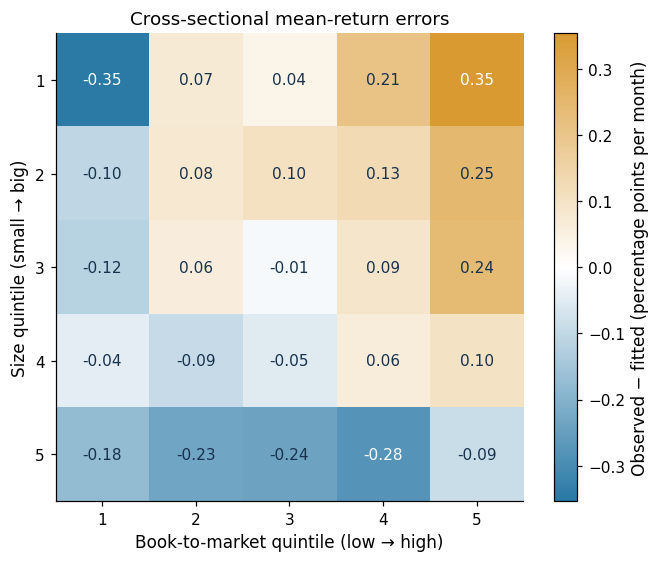

In [7]:
error_grid=pricing_errors.reindex(asset_order).to_numpy().reshape(5,5)*100
lim=np.abs(error_grid).max()
fig,ax=plt.subplots(figsize=(6.8,5),layout="constrained")
im=ax.imshow(error_grid,cmap=SIGNED,norm=TwoSlopeNorm(0,vmin=-lim,vmax=lim),aspect="equal")
for (row,col),value in np.ndenumerate(error_grid):
    ax.text(col,row,f"{value:.2f}",ha="center",va="center",fontsize=10,color="white" if abs(value)>.72*lim else NAVY)
ax.set(xticks=range(5),xticklabels=range(1,6),yticks=range(5),yticklabels=range(1,6),xlabel="Book-to-market quintile (low → high)",ylabel="Size quintile (small → big)",title="Cross-sectional mean-return errors")
fig.colorbar(im,ax=ax,label="Observed − fitted (percentage points per month)")
plt.show()

Among the smallest portfolios, the low-B/M portfolio falls approximately 0.346 percentage points per month below the fitted mean, while the high-B/M portfolio sits approximately 0.354 points above it. All five largest-size portfolios have negative errors. The remaining pattern is therefore connected to the portfolios' characteristic layout, rather than merely a single unusual cell.

Average absolute error is approximately 0.143 percentage points per month, and root-mean-squared error is approximately 0.172 points. These describe the magnitude of unexplained historical means. They are neither significance tests nor expected profits available to a future trading strategy. Because the regression includes an intercept, signed errors average to zero across the equally weighted test assets, which is why absolute magnitudes are useful.

### 2.4 What the application establishes

In this cross-section, estimated market beta alone does not closely organize the historical mean returns. The fitted exposure price is imprecise, the fitted means vary little, and structured cross-sectional errors remain. The conclusion concerns these 25 portfolios and this sample. It does not identify whether the departures reflect omitted factors, mispricing, estimation error, or the test-asset design.

The analysis estimates betas from the same full sample used for the cross-sectional comparisons. It is a retrospective pricing exercise, not an implementable sequence of portfolio decisions. The reported HAC uncertainty also conditions on those estimated betas, rather than fully accounting for both estimation stages. The data show what happened in sample, without establishing out-of-sample investment performance.

The two-pass method extends to multiple exposures through the general restriction introduced in Section 1. Here the single market exposure makes the estimation and interpretation visible. Notebook 06 develops the opportunities created by combining investments, while Notebook 07 compares factor models using time-series alpha restrictions.

## References
- Fama, E. F., and French, K. R. (1993). Common risk factors in the returns on stocks and bonds. *Journal of Financial Economics*, 33(1), 3–56. [DOI](https://doi.org/10.1016/0304-405X(93)90023-5).
- Fama, E. F., and French, K. R. (2015). A five-factor asset pricing model. *Journal of Financial Economics*, 116(1), 1–22. [DOI](https://doi.org/10.1016/j.jfineco.2014.10.010).
- Kenneth French, [five-factor construction documentation](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_5_factors_2x3.html).
- Fama, E. F., and MacBeth, J. D. (1973). Risk, return, and equilibrium: empirical tests. *Journal of Political Economy*, 81(3), 607–636. [DOI](https://doi.org/10.1086/260061).
- Shanken, J. (1992). On the estimation of beta-pricing models. *Review of Financial Studies*, 5(1), 1–33. [DOI](https://doi.org/10.1093/rfs/5.1.1).
- Cochrane, J. H. (2005). *Asset Pricing*, revised edition. Princeton University Press. [Author](https://www.johnhcochrane.com/asset-pricing).
- Newey and West (1987), covariance inference. See Notebook 04 for the original reference.